# FairRate vs. Signal Blind Reputation Baselines

This notebook runs the FairRate pipeline from `FairRate_Notebook_v3.ipynb` and compares it with six reputation aggregators that use only observed ratings and rater and driver identities.

| Method | Signals used |
|---|---|
| Observed Biased | none |
| Context-Calibrated | objective trip context |
| Raw Driver Mean | ratings |
| Trimmed Mean (10%) | ratings |
| Median-Based Correction | ratings |
| Robust Averaging (Huber) | ratings |
| Bayesian Reputation Filtering | ratings, global prior |
| Reliability-Only Filtering | ratings, rater identity |
| Full FairRate | context, earlier rater history, review text, telemetry |

**Trip level.** Each method is scored per trip against the reference rating. Driver level baselines assign one score per driver, computed from all of that driver's observed ratings, to each of the driver's trips.

**Driver level.** Each method gives one score per driver, scored against the mean reference rating of that driver. FairRate uses the mean of its corrected ratings.

## 1. Setup

In [1]:
!pip install vaderSentiment lightgbm catboost xgboost openpyxl adjustText -q

In [2]:
import pandas as pd, numpy as np, warnings
from pathlib import Path

from sklearn.model_selection import KFold, TimeSeriesSplit
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_extraction.text import TfidfVectorizer

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from scipy.special import expit
from scipy.stats import wilcoxon, ttest_rel, trim_mean

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
np.random.seed(42)

C1, C2, C3, C4, C5, C6 = "#2E86AB", "#E05263", "#3DAA6D", "#F5A623", "#7B68EE", "#888888"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 600, "savefig.bbox": "tight",
    "font.family": "serif", "font.size": 10, "axes.titlesize": 11,
    "axes.labelsize": 10, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.fontsize": 8, "figure.figsize": (7, 4.5),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.2, "grid.linestyle": "--",
})

FIG = Path("all_figures"); FIG.mkdir(exist_ok=True)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

def savefig(name, fig=None):
    f = fig or plt.gcf()
    f.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    f.savefig(FIG / f"{name}.png", bbox_inches="tight")

def _rmse(y, p):
    return float(np.sqrt(mean_squared_error(y, p)))

def metric_row(name, y, p):
    return {"Method": name, "MAE": mean_absolute_error(y, p), "RMSE": _rmse(y, p), "R2": r2_score(y, p)}

## 2. Data and preprocessing

In [3]:
DATA_PATH = "biased_trip_reviews_final.xlsx"
df_raw = pd.read_excel(DATA_PATH)
print(f"Shape: {df_raw.shape}")

Shape: (9158, 49)


In [4]:
df = df_raw.copy()
df["observed"] = df["star_rating"]
df["clean_ref"] = df["original_star_rating"]
df["review_text_final"] = df["biased_review_text"].fillna(df["review_text"]).fillna("")

for col in ["request_time", "pickup_time", "dropoff_time"]:
    df[col] = pd.to_datetime(df[col], errors="coerce")

def _wbin(x):
    if pd.isna(x): return "unknown"
    return "short" if x < 3 else ("medium" if x < 8 else "long")
def _weath(row):
    if row["pickup_is_snow"] == True: return "snow"
    if row["pickup_is_rain"] == True: return "rain"
    if row["pickup_wind_kph"] >= 30: return "windy"
    return "clear"
def _csbin(x):
    if pd.isna(x): return "unknown"
    return "low" if x < 0.10 else ("medium" if x < 0.30 else "high")
def _dbin(x):
    if pd.isna(x): return "unknown"
    return "short" if x < 2 else ("medium" if x < 6 else "long")

df["wait_bin"] = df["wait_time_mins"].apply(_wbin)
df["weather_bin"] = df.apply(_weath, axis=1)
df["cost_shock_bin"] = df["cost_shock_ratio"].apply(_csbin)
df["distance_bin"] = df["trip_distance"].apply(_dbin)

df = df.sort_values("pickup_time", kind="mergesort").reset_index(drop=True)

print(f"Trips without a weather record: {df['pickup_temp_c'].isna().sum()}")
print(df.loc[df["pickup_temp_c"].isna(), "weather_bin"].value_counts().to_dict())
for b in ["wait_bin", "weather_bin", "cost_shock_bin", "distance_bin"]:
    print(b, df[b].value_counts().to_dict())

Trips without a weather record: 40
{'clear': 40}
wait_bin {'medium': 5081, 'short': 3200, 'long': 877}
weather_bin {'clear': 7652, 'rain': 1356, 'snow': 133, 'windy': 17}
cost_shock_bin {'low': 5692, 'medium': 2812, 'high': 654}
distance_bin {'medium': 3380, 'short': 3120, 'long': 2658}


## 3. Context model (CatBoost, predictions from five consecutive time blocks)

In [5]:
CTX_NUM = ["trip_distance", "fare_amount", "driver_pay", "driver_pay_ratio",
           "tip_amount", "tip_ratio", "speed_mph", "wait_time_mins",
           "total_surcharges", "cost_shock_ratio", "pickup_hour", "pickup_dow",
           "pickup_temp_c", "pickup_precip_mm", "pickup_snow_cm", "pickup_wind_kph",
           "duration_mins"]
CTX_CAT = ["is_weekend", "is_late_night", "pickup_is_snow", "pickup_is_rain",
           "wait_bin", "weather_bin", "cost_shock_bin", "distance_bin"]
for c in CTX_CAT:
    df[c] = df[c].astype(str)

X_all = df[CTX_NUM + CTX_CAT]
y_all = df["observed"]

preprocessor = ColumnTransformer([
    ("num", SkPipeline([("imp", SimpleImputer(strategy="median"))]), CTX_NUM),
    ("cat", SkPipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CTX_CAT),
])

def catboost_pipe():
    return SkPipeline([("pre", preprocessor),
                       ("model", CatBoostRegressor(iterations=500, depth=6, learning_rate=0.05,
                                                   random_seed=42, verbose=0))])

In [6]:
n = len(df)
oof = np.full(n, np.nan)
fold_rows = []
for k, (tr_i, te_i) in enumerate(KFold(n_splits=5, shuffle=False).split(X_all), start=1):
    pipe = catboost_pipe().fit(X_all.iloc[tr_i], y_all.iloc[tr_i])
    oof[te_i] = pipe.predict(X_all.iloc[te_i])
    fold_rows.append({"Fold": k,
                      "Test from": df["pickup_time"].iloc[te_i[0]].date(),
                      "Test to": df["pickup_time"].iloc[te_i[-1]].date(),
                      "Trained on later trips": bool(tr_i.max() > te_i.max()),
                      "MAE": mean_absolute_error(y_all.iloc[te_i], oof[te_i]),
                      "RMSE": _rmse(y_all.iloc[te_i], oof[te_i]),
                      "R2": r2_score(y_all.iloc[te_i], oof[te_i])})
cv_df = pd.DataFrame(fold_rows)
print(cv_df.round(4).to_string(index=False))
print(f"MAE {cv_df['MAE'].mean():.4f} +/- {cv_df['MAE'].std():.4f}, "
      f"RMSE {cv_df['RMSE'].mean():.4f} +/- {cv_df['RMSE'].std():.4f}, "
      f"R2 {cv_df['R2'].mean():.4f} +/- {cv_df['R2'].std():.4f}")

df["ctx_expected"] = oof
df["ctx_residual"] = df["observed"] - df["ctx_expected"]
print(f"Context residual mean {df['ctx_residual'].mean():.4f}, std {df['ctx_residual'].std():.4f}")

 Fold  Test from    Test to  Trained on later trips    MAE   RMSE     R2
    1 2025-01-01 2025-02-09                    True 0.2760 0.3494 0.6901
    2 2025-02-09 2025-03-27                    True 0.2978 0.3776 0.6643
    3 2025-03-27 2025-06-11                    True 0.2885 0.3724 0.6739
    4 2025-06-11 2025-07-17                    True 0.2929 0.3716 0.6635
    5 2025-07-17 2025-09-30                   False 0.2927 0.3715 0.6578
MAE 0.2896 +/- 0.0083, RMSE 0.3685 +/- 0.0109, R2 0.6699 +/- 0.0127
Context residual mean -0.0011, std 0.3686


## 4. Rater score from earlier trips only

In [7]:
analyzer = SentimentIntensityAnalyzer()
df["sentiment"] = df["review_text_final"].apply(lambda x: analyzer.polarity_scores(str(x))["compound"])
df["is_extreme"] = df["star_rating_int"].isin([1, 5]).astype(int)
df["is_inconsistent"] = (((df["sentiment"] > 0.3) & (df["observed"] <= 2.5)) |
                         ((df["sentiment"] < -0.3) & (df["observed"] >= 4.0))).astype(int)

g = df.groupby("rider_id", sort=False)
prev_n = g.cumcount()

def past_mean(col):
    return ((g[col].cumsum() - df[col]) / prev_n.replace(0, np.nan)).fillna(0.0)

df["E_r"] = past_mean("is_extreme")
df["I_r"] = past_mean("is_inconsistent")
df["H_r"] = (-past_mean("ctx_residual")).clip(0, 0.5)

conc, seen = [], {}
for r, d in zip(df["rider_id"], df["driver_id"]):
    h = seen.setdefault(r, {})
    tot = sum(h.values())
    conc.append(max(h.values()) / tot if tot else 0.0)
    h[d] = h.get(d, 0) + 1
df["C_r"] = conc

def _mat(k):
    if k <= 1: return 0.1
    if k <= 3: return 0.3
    if k <= 7: return 0.6
    return 1.0
df["prev_trips"] = prev_n
df["M_r"] = prev_n.apply(_mat)

df["reliability"] = expit(1.5 - 3.0 * df["E_r"] - 3.0 * df["I_r"] - 2.0 * df["C_r"]
                          - 2.5 * df["H_r"] + 1.5 * df["M_r"])

print(f"Riders with at least one trip: {df['rider_id'].nunique()}")
print(f"Trips with no earlier history for the rider: {(prev_n == 0).sum()}")
print(df["reliability"].describe().round(4).to_dict())

Riders with at least one trip: 783
Trips with no earlier history for the rider: 783
{'count': 9158.0, 'mean': 0.7796, 'std': 0.192, 'min': 0.01, '25%': 0.7211, '50%': 0.8414, '75%': 0.9101, 'max': 0.9483}


## 5. Review category

In [8]:
DRIVER_KW = ["rude", "unsafe", "wrong route", "bad driving", "unprofessional",
             "late pickup", "reckless", "speeding", "ignored", "unfriendly",
             "aggressive", "could have been more professional",
             "less comfortable than expected", "did not feel safe"]
PLATFORM_KW = ["surge", "overpriced", "expensive", "surcharge", "extra fee",
               "unexpected fee", "charged too much", "app crash",
               "cancellation fee", "billing", "overcharged",
               "not worth the price", "not worth it", "for the price",
               "too much money", "pricing"]
ENVIRON_KW = ["traffic", "rain", "snow", "road", "construction",
              "accident", "congestion", "storm", "delay", "flooding",
              "weather", "cold", "icy", "slippery"]

def _kw_classify(text, sentiment):
    t = str(text).lower()
    d = sum(k in t for k in DRIVER_KW)
    p = sum(k in t for k in PLATFORM_KW)
    e = sum(k in t for k in ENVIRON_KW)
    if sentiment < 0.0:
        p += sum(k in t for k in ["fare", "fee", "price", "payment", "charged"]) * 0.5
        d += ("driver" in t) * 0.3
    scores = {"DRIVER": d, "PLATFORM": p, "ENVIRONMENT": e}
    best = max(scores, key=scores.get)
    return best if scores[best] > 0 else "UNKNOWN"

df["kw_label"] = [_kw_classify(t, s) for t, s in zip(df["review_text_final"], df["sentiment"])]
tfidf = TfidfVectorizer(max_features=500, stop_words="english", ngram_range=(1, 2))
X_text = tfidf.fit_transform(df["review_text_final"])
clf = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced").fit(X_text, df["kw_label"])
df["review_cat"] = clf.predict(X_text)
print(df["review_cat"].value_counts().to_dict())
print(f"Agreement between classifier and keyword labels: {(df['review_cat'] == df['kw_label']).mean():.3f}")

{'ENVIRONMENT': 5381, 'PLATFORM': 2321, 'UNKNOWN': 1146, 'DRIVER': 310}
Agreement between classifier and keyword labels: 0.880


## 6. Telemetry score

In [9]:
def _mm(s):
    s = s.astype(float)
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

W_WAIT, W_CSHOCK, W_SURCH, W_LOSPD = 0.25, 0.25, 0.20, 0.15
df["wait_n"] = _mm(df["wait_time_mins"])
df["cshock_n"] = _mm(df["cost_shock_ratio"])
df["surch_n"] = _mm(df["total_surcharges"])
df["lospd_n"] = 1 - _mm(df["speed_mph"])
df["telemetry_q"] = (1 - (W_WAIT * df["wait_n"] + W_CSHOCK * df["cshock_n"]
                          + W_SURCH * df["surch_n"] + W_LOSPD * df["lospd_n"])).clip(0, 1)

surch_check = (df["tolls"] + df["congestion_surcharge"] + df["airport_fee"] + df["cbd_congestion_fee"] - df["total_surcharges"]).abs().max()
cs_check = (df["total_surcharges"] / df["fare_amount"] - df["cost_shock_ratio"]).abs().max()
print(f"Max gap between total_surcharges and the sum of its parts: {surch_check:.4f}")
print(f"Max gap between cost_shock_ratio and surcharges divided by fare: {cs_check:.6f}")
print(df["telemetry_q"].describe().round(4).to_dict())
print(f"Share of trips with a positive telemetry term: {(df['telemetry_q'] > 0.5).mean():.3f}")

Max gap between total_surcharges and the sum of its parts: 0.0000
Max gap between cost_shock_ratio and surcharges divided by fare: 0.000000
{'count': 9158.0, 'mean': 0.8316, 'std': 0.0462, 'min': 0.556, '25%': 0.8022, '50%': 0.8441, '75%': 0.8624, 'max': 0.9752}
Share of trips with a positive telemetry term: 1.000


## 7. Correction and weight selection

In [10]:
CAT_AMP = {"DRIVER": 0.05, "PLATFORM": 0.90, "ENVIRONMENT": 0.85, "UNKNOWN": 0.35}
TAU = 1.0
MAX_CORR = 2.0
ALPHA_GRID = np.round(np.arange(0.2, 1.6, 0.1), 2)
BETA_GRID = np.round(np.arange(0.1, 1.2, 0.1), 2)
GAMMA_GRID = np.round(np.arange(0.1, 1.2, 0.1), 2)

phi_rev = df["review_cat"].map(CAT_AMP)
phi_rel = 1 - df["reliability"]
phi_tel = (df["telemetry_q"] - 0.5).clip(0, 0.5)

def compute_fairrate(alpha, beta, gamma, tau=TAU, max_corr=MAX_CORR, data=None):
    d = df if data is None else data
    bounded_res = np.tanh(d["ctx_residual"] / tau) * tau
    signal = (alpha * d["review_cat"].map(CAT_AMP)
              + beta * (1 - d["reliability"])
              + gamma * (d["telemetry_q"] - 0.5).clip(0, 0.5))
    correction = (signal * (-bounded_res)).clip(-max_corr, max_corr)
    return (d["observed"] + correction).clip(1.0, 5.0), correction

def grid_search(mask=None):
    m = np.ones(len(df), bool) if mask is None else np.asarray(mask)
    best_mae, best = np.inf, None
    for a in ALPHA_GRID:
        for b in BETA_GRID:
            for c in GAMMA_GRID:
                fr, _ = compute_fairrate(a, b, c)
                mae = mean_absolute_error(df["clean_ref"][m], fr[m])
                if mae < best_mae:
                    best_mae, best = mae, (a, b, c)
    return best, best_mae

In [11]:
(ALPHA_OPT, BETA_OPT, GAMMA_OPT), _ = grid_search()
df["fairrate"], df["correction"] = compute_fairrate(ALPHA_OPT, BETA_OPT, GAMMA_OPT)
print(f"alpha={ALPHA_OPT}, beta={BETA_OPT}, gamma={GAMMA_OPT}")
print(f"MAE observed {mean_absolute_error(df['clean_ref'], df['observed']):.4f}, FairRate {mean_absolute_error(df['clean_ref'], df['fairrate']):.4f}")

alpha=0.2, beta=0.6, gamma=0.8
MAE observed 0.2779, FairRate 0.2437


## 8. Signal blind baselines

In [12]:
def raw_driver_mean(d):
    return d.groupby("driver_id")["observed"].mean()

def trimmed_mean_by_driver(d, prop=0.10):
    def f(x):
        x = np.asarray(x, float)
        return float(np.median(x)) if len(x) < 5 else float(trim_mean(x, prop))
    return d.groupby("driver_id")["observed"].apply(f)

def median_by_driver(d):
    return d.groupby("driver_id")["observed"].median()

def _huber_location(x, k=1.345, n_iter=40, tol=1e-4):
    x = np.asarray(x, float)
    if len(x) < 3:
        return float(np.mean(x))
    mu = float(np.median(x))
    s = 1.4826 * float(np.median(np.abs(x - mu))) + 1e-6
    for _ in range(n_iter):
        r = (x - mu) / s
        w = np.where(np.abs(r) <= k, 1.0, k / np.abs(r))
        new = float(np.sum(w * x) / np.sum(w))
        if abs(new - mu) < tol:
            return new
        mu = new
    return mu

def robust_huber_by_driver(d):
    return d.groupby("driver_id")["observed"].apply(lambda x: _huber_location(x.values))

def bayesian_reputation_filter(d, prior_strength=4.0, q=0.10):
    mu0 = float(d["observed"].mean())
    out = {}
    for drv, x in d.groupby("driver_id")["observed"]:
        v = np.sort(x.values.astype(float))
        if len(v) >= 5:
            lo, hi = np.quantile(v, q), np.quantile(v, 1 - q)
            kept = v[(v >= lo) & (v <= hi)]
            kept = kept if len(kept) else v
        else:
            kept = v
        out[drv] = (len(kept) * kept.mean() + prior_strength * mu0) / (len(kept) + prior_strength)
    return pd.Series(out)

def reliability_only_filter(d, n_iter=20, eps=1e-3):
    obs = d[["rider_id", "driver_id", "observed"]].copy()
    s = obs.groupby("driver_id")["observed"].mean()
    for _ in range(n_iter):
        obs["s"] = obs["driver_id"].map(s)
        err = obs.assign(e=(obs["observed"] - obs["s"]) ** 2).groupby("rider_id")["e"].mean()
        rel = 1.0 / (err + eps)
        obs["w"] = obs["rider_id"].map(rel / rel.mean())
        s_new = (obs.assign(wx=obs["w"] * obs["observed"]).groupby("driver_id")["wx"].sum()
                 / obs.groupby("driver_id")["w"].sum())
        if (s_new - s).abs().max() < 1e-4:
            return s_new
        s = s_new
    return s

In [13]:
driver_est = pd.DataFrame(index=sorted(df["driver_id"].unique()))
driver_est.index.name = "driver_id"
driver_est["Raw Driver Mean"] = raw_driver_mean(df)
driver_est["Trimmed Mean"] = trimmed_mean_by_driver(df)
driver_est["Median-Based Correction"] = median_by_driver(df)
driver_est["Robust Averaging (Huber)"] = robust_huber_by_driver(df)
driver_est["Bayesian Reputation Filtering"] = bayesian_reputation_filter(df)
driver_est["Reliability-Only Filtering"] = reliability_only_filter(df)
driver_est["Full FairRate"] = df.groupby("driver_id")["fairrate"].mean()
print(driver_est.round(3).head())

             Raw Driver Mean  Trimmed Mean  Median-Based Correction  \
driver_id                                                             
DRIVER_0002            3.355         3.378                      3.3   
DRIVER_0003            3.570         3.582                      3.6   
DRIVER_0004            3.361         3.396                      3.4   
DRIVER_0005            3.414         3.415                      3.3   
DRIVER_0006            3.260         3.271                      3.3   

             Robust Averaging (Huber)  Bayesian Reputation Filtering  \
driver_id                                                              
DRIVER_0002                     3.376                          3.387   
DRIVER_0003                     3.578                          3.569   
DRIVER_0004                     3.400                          3.435   
DRIVER_0005                     3.415                          3.419   
DRIVER_0006                     3.274                          3.306  

## 9. Comparison

In [14]:
trip_preds = {"Observed Biased": df["observed"], "Context-Calibrated": df["ctx_expected"]}
for m in driver_est.columns:
    if m != "Full FairRate":
        trip_preds[m] = df["driver_id"].map(driver_est[m])
trip_preds["Full FairRate"] = df["fairrate"]

trip_cmp = pd.DataFrame([metric_row(m, df["clean_ref"], p) for m, p in trip_preds.items()])
obs_mae = trip_cmp.loc[trip_cmp["Method"] == "Observed Biased", "MAE"].iloc[0]
trip_cmp["MAE Reduction %"] = (1 - trip_cmp["MAE"] / obs_mae) * 100
trip_cmp = trip_cmp.sort_values("MAE").reset_index(drop=True)

drv_target = df.groupby("driver_id")["clean_ref"].mean().reindex(driver_est.index)
drv_cmp = pd.DataFrame([metric_row(m, drv_target.values, driver_est[m].values) for m in driver_est.columns])
raw_drv = drv_cmp.loc[drv_cmp["Method"] == "Raw Driver Mean", "MAE"].iloc[0]
drv_cmp["MAE Reduction %"] = (1 - drv_cmp["MAE"] / raw_drv) * 100
drv_cmp = drv_cmp.sort_values("MAE").reset_index(drop=True)

print("Trip level, against the reference rating")
print(trip_cmp.round(4).to_string(index=False))
print()
print("Driver level, against the mean reference rating of each driver")
print(drv_cmp.round(4).to_string(index=False))

trip_cmp.to_csv("fairrate_vs_baselines_trip.csv", index=False)
drv_cmp.to_csv("fairrate_vs_baselines_driver.csv", index=False)

Trip level, against the reference rating
                       Method    MAE   RMSE      R2  MAE Reduction %
                Full FairRate 0.2437 0.3082  0.6674          12.3255
              Observed Biased 0.2779 0.3602  0.5455           0.0000
           Context-Calibrated 0.2816 0.3534  0.5626          -1.3059
   Reliability-Only Filtering 0.4327 0.5378 -0.0131         -55.6882
      Median-Based Correction 0.4329 0.5401 -0.0217         -55.7537
Bayesian Reputation Filtering 0.4343 0.5389 -0.0172         -56.2750
     Robust Averaging (Huber) 0.4354 0.5402 -0.0219         -56.6690
                 Trimmed Mean 0.4357 0.5402 -0.0221         -56.7504
              Raw Driver Mean 0.4419 0.5456 -0.0425         -58.9910

Driver level, against the mean reference rating of each driver
                       Method    MAE   RMSE      R2  MAE Reduction %
   Reliability-Only Filtering 0.1085 0.1238 -0.1909          23.7068
      Median-Based Correction 0.1107 0.1339 -0.3928          22.155

## 10. Figure

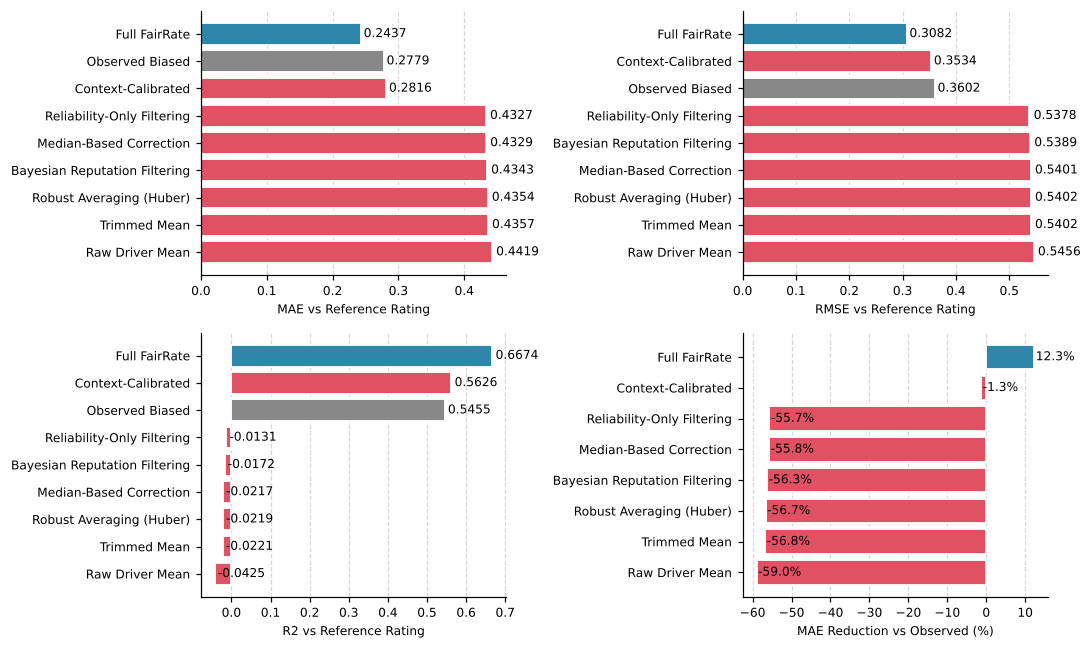

In [15]:
def _cols(ms):
    return [C1 if m == "Full FairRate" else (C6 if m == "Observed Biased" else C2) for m in ms]

def _style(ax):
    ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
    ax.xaxis.grid(True, linestyle="--", alpha=0.5); ax.yaxis.grid(False); ax.set_axisbelow(True)

plt.rcParams.update({"font.family": "sans-serif", "axes.labelsize": 8, "xtick.labelsize": 8, "ytick.labelsize": 8})
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col, asc, fmt in [(axes[0, 0], "MAE", False, "{:.4f}"), (axes[0, 1], "RMSE", False, "{:.4f}"),
                          (axes[1, 0], "R2", True, "{:.4f}")]:
    b = trip_cmp.sort_values(col, ascending=asc)
    ax.barh(b["Method"], b[col], color=_cols(b["Method"]), edgecolor="white", linewidth=1.2)
    for i, v in enumerate(b[col]):
        ax.text(v + (abs(v) * 0.015 if col != "R2" else 0.008), i, fmt.format(v), va="center", fontsize=8)
    ax.set_xlabel(f"{col} vs Reference Rating"); _style(ax)
ax = axes[1, 1]
b = trip_cmp[trip_cmp["Method"] != "Observed Biased"].sort_values("MAE Reduction %")
ax.barh(b["Method"], b["MAE Reduction %"], color=_cols(b["Method"]), edgecolor="white", linewidth=1.2)
for i, v in enumerate(b["MAE Reduction %"]):
    ax.text(v + 0.4, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("MAE Reduction vs Observed (%)"); _style(ax)
plt.tight_layout()
savefig("fairrate_vs_baselines")
plt.show()

## 11. Significance against the strongest baseline

In [16]:
best_base = trip_cmp[~trip_cmp["Method"].isin(["Full FairRate", "Observed Biased", "Context-Calibrated"])].iloc[0]["Method"]
ae_fair = (df["clean_ref"] - df["fairrate"]).abs().values
ae_base = (df["clean_ref"] - trip_preds[best_base]).abs().values
diff = ae_base - ae_fair
print(f"Strongest trip level baseline: {best_base}")
print(f"Trip MAE {best_base}: {ae_base.mean():.4f}, Full FairRate: {ae_fair.mean():.4f}")
print(f"Trips where FairRate has lower error: {(diff > 0).mean() * 100:.1f}%")
print(f"Wilcoxon p={wilcoxon(ae_base, ae_fair, alternative='greater').pvalue:.3e}, paired t p={ttest_rel(ae_base, ae_fair).pvalue:.3e}")
best_drv = drv_cmp.iloc[0]["Method"]
fr_drv = drv_cmp.loc[drv_cmp["Method"] == "Full FairRate", "MAE"].iloc[0]
print(f"Best driver level method: {best_drv} (MAE {drv_cmp.iloc[0]['MAE']:.4f}); Full FairRate driver level MAE {fr_drv:.4f}")

Strongest trip level baseline: Reliability-Only Filtering
Trip MAE Reliability-Only Filtering: 0.4327, Full FairRate: 0.2437
Trips where FairRate has lower error: 68.7%
Wilcoxon p=0.000e+00, paired t p=0.000e+00
Best driver level method: Reliability-Only Filtering (MAE 0.1085); Full FairRate driver level MAE 0.1431
